## 09 — CIBERSORTx vs. XDec k=13 comparison

### Aim
* Compare XDec's autotuned **k=13** run (this track's best floor-respecting stability candidate, 0.9968 — see [k-sweep notebook](./08_k_candidates_profile_reference_heatmaps.ipynb) against CIBERSORTx, using CIBERSORTx's **own automatically-selected genes** (not the paper's 282-gene list).
  * [the same-gene-list approach](../scripts/12_cibersortx_vs_xdec_comparison.ipynb) did undermine the performance of CIBERSORTx substantially.

* **Figures 1 and 2 use hierarchical clustering** (`row_cluster=True, col_cluster=True`) rather than the fixed profile-number / cell-type order used everywhere else in this project. The fixed-order originals (and the reasoning for why fixed order is usually preferred as a *validation* check) are archived at `figures/archive/` — this notebook instead asks whether unsupervised clustering on the correlation values recovers the same structure independently, without being told the labels.

### Input
* **CIBERSORTx**
1. `data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx/CIBERSORTx_sigmatrix_Adjusted.txt` — CIBERSORTx's own auto-built signature matrix (**3,732 genes** it selected itself from the Peng reference, not the paper gene list); column labels are shifted by one position as supplied (discovered in notebook 12) and corrected here before use
2. `data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx/CIBERSORTx_Adjusted.txt` — the matching per-sample fractions, same label-shift correction applied
* **xDEC**
1. `data/deconvolution/xdec/paper_style_ref/{refs_pseudobulk_raw.tsv,ref_metadata_pseudobulk_raw.tsv}` — the Run D pseudobulk reference used for both Figure 1 and Figure 2
2. `data/deconvolution/xdec/gene_lists/xdec_chi_table_s3_genes.txt` — paper's 282-gene Table S3 list, used for Figure 1 (matching notebook 08's own gene list for the k=13 fit)
3. `xdec_autotuned_n150/stage1_k13/{proportions.tsv,correlation.tsv,cell_type_profiles.tsv}` — XDec k=13 fit, n=150
* Note: Both methods used **the same 150 [filtered samples](../paper_duplication/sample_filtering.md)**. Adjusting for tumor purity is also important for accurate deconvolution. And there's no normal tissue in the 150 samples.
  
### Output
* **Figure 1 (clustered)**: XDec k=13 profile × Run D reference correlation, both axes hierarchically clustered, with dendrograms
* **Figure 2 (clustered)**: the same visualization applied to CIBERSORTx's own signature matrix (own auto-selected genes) × the identical Run-D-pseudobulk reference
* **Figure 3**: per-reference-cell-type proportion scatter, XDec k=13 (best-matching profile) vs. CIBERSORTx (n=150, same cohort), with a red y=x reference line per panel — unchanged from the original version of this notebook

### Steps
* Correct CIBERSORTx's column-label shift (same bug as notebook 12, re-verified here against independent bulk markers)
* Build Figure 1 and Figure 2 as hierarchically-clustered correlation heatmaps against the same Run D reference
* Restrict CIBERSORTx's fractions to the n=150 cohort shared with XDec k=13 and build the per-type proportion scatter (Figure 3)

### Result
* **Label-shift bug reconfirmed**: same one-position column shift as notebook 12's finding (summed marker r: -0.15 as-supplied vs. +2.86 corrected) — now confirmed across two independent CIBERSORTx Docker runs.
* **Figure 2 (CIBERSORTx) independently recovers almost exactly the immune/stromal/epithelial three-way grouping this whole project keeps finding**, with zero label information given to the clustering algorithm — column clustering sorts the 909 reference replicates into three contiguous mega-blocks (immune: T cell + B lineage + myeloid + neural; stromal: endothelial + fibroblast + stellate; epithelial: enteroendocrine + acinar + ductal), and row clustering groups CIBERSORTx's own 10 signature rows into the identical three groups.
* **Figure 1 (XDec k=13) clusters much less cleanly**: enteroendocrine, ductal, and myeloid each survive as their own contiguous column block, but T cell / lymphocyte of B lineage / neural interleave heavily, as do fibroblast / stellate / neural. The row dendrogram splits the 13 profiles into a tight "broad/ambiguous" cluster (Profile_9, 13, 7, 3, 6 — matching notebook 08's by-eye flags), a looser middle cluster (Profile_1, 11, 2, 5), and a near-flat "dead profile" cluster (Profile_4, 10, 8, 12 — also matching notebook 08).
* **Figure 3 proportions split cleanly into two groups**: `lymphocyte of B lineage` (r=0.80), `T cell` (r=0.80), `fibroblast` (r=0.78), `myeloid leukocyte` (r=0.74), and `pancreatic ductal cell` (r=0.70) correlate strongly and significantly (all p<1e-22); `pancreatic stellate cell`, `pancreatic acinar cell`, `neural cell`, `enteroendocrine cell`, and `blood vessel endothelial cell` show no meaningful relationship. **Even the five strong-correlation panels mostly sit well below the red y=x line** — CIBERSORTx systematically estimates larger proportions than XDec k=13 for the same samples, despite close rank agreement.

### Conclusion
* The clustering comparison (Figures 1-2) makes the gap between a supervised and an unsupervised method unusually visible: CIBERSORTx's immune/stromal/epithelial structure is recoverable from the correlation data with no label information at all, while XDec's k=13 profiles require already knowing which profile is which — and even then, several profiles explain each other (cluster together) better than they explain any single reference cell type. **Figure 3 adds that where the two tools do agree, it is agreement on *ranking*, not on *magnitude***: CIBERSORTx consistently reports larger fractions than XDec for the same samples. Together, this is the most complete three-way picture in this project of where XDec's unsupervised profiles are trustworthy (ductal, fibroblast, and the three immune types, at least in relative terms) and where the shared/ambiguous/dead profile problem (documented since notebook 08) measurably costs external, cross-tool validity.




### Comparison from my empirical experience

Technically, CIBERSORTx requires a reference and uses it as a quantitative template, whereas XDec is reference-optional: it uses a reference only to select informative genes and then performs unsupervised deconvolution based solely on the bulk expression data. This leads to different kinds of results. CIBERSORTx produces definitive, labeled cell-type estimates, but it is not robust to reference mismatch, because it assumes the reference captures the true cellular composition of the bulk samples. XDec, in contrast, addresses a harder question: discovering cell states that no one has pre-labeled. This makes XDec more appropriate for studying the tumor microenvironment(TEM), since TEM is different from normal tissue and quite complex(e.g. tissue tumor cells are often absent from single-cell references derived from normal tissue). However, XDec remains limited by signal distortion from copy-number changes and ectopic expression.

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import pearsonr, spearmanr

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "tools/XDec_SM/python/xdec.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start from progress/ or one of its subdirectories.")
os.chdir(ROOT)

XDEC_DIR = "data/deconvolution/xdec"
NEW_RUN_DIR = "xdec_autotuned_n150"
CIBER_DIR = "data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx"
K = 13

mpl.rcParams.update({"font.family": "sans-serif", "font.size": 8, "axes.linewidth": 0.6, "pdf.fonttype": 42})
SEQ_BLUE_STEPS = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
                  "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
seq_blue = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE_STEPS, N=256)

REFERENCE_CELL_TYPES = [
    "T cell", "blood vessel endothelial cell", "enteroendocrine cell", "fibroblast",
    "lymphocyte of B lineage", "myeloid leukocyte", "neural cell",
    "pancreatic acinar cell", "pancreatic ductal cell", "pancreatic stellate cell",
]
cell_type_order = [
    "pancreatic acinar cell", "pancreatic ductal cell", "enteroendocrine cell",
    "pancreatic stellate cell", "fibroblast", "blood vessel endothelial cell", "neural cell",
    "T cell", "lymphocyte of B lineage", "myeloid leukocyte",
]
cell_palette = dict(zip(cell_type_order, sns.color_palette("tab10", len(cell_type_order))))

stage1_dir_k13 = os.path.join(NEW_RUN_DIR, f"stage1_k{K}")
profiles_k13 = pd.read_csv(os.path.join(stage1_dir_k13, "cell_type_profiles.tsv"), sep="\t", index_col=0)
profile_order = [f"Profile_{i}" for i in range(1, K + 1)]
proportions_k13 = pd.read_csv(os.path.join(stage1_dir_k13, "proportions.tsv"), sep="\t", index_col=0)
correlation_k13 = pd.read_csv(os.path.join(stage1_dir_k13, "correlation.tsv"), sep="\t", index_col=0)
if proportions_k13.shape != (150, K):
    raise ValueError(f"Expected 150x{K} XDec k=13 proportions, got {proportions_k13.shape}")
if list(correlation_k13.index) != REFERENCE_CELL_TYPES:
    raise ValueError("Unexpected reference row order in k=13 correlation.tsv")

assignment_k13 = pd.DataFrame({
    "best_profile": correlation_k13.idxmax(axis=1),
    "best_r": correlation_k13.max(axis=1),
})
print("XDec k=13: per-reference-type best-correlating profile")
assignment_k13.sort_values("best_r", ascending=False)


XDec k=13: per-reference-type best-correlating profile


,best_profile,best_r
pancreatic ductal cell,Profile_13,0.437358
fibroblast,Profile_1,0.404556
lymphocyte of B lineage,Profile_5,0.343204
myeloid leukocyte,Profile_2,0.335383
blood vessel endothelial cell,Profile_6,0.325077
T cell,Profile_5,0.315806
pancreatic stellate cell,Profile_1,0.315322
neural cell,Profile_7,0.308050
pancreatic acinar cell,Profile_7,0.219143
enteroendocrine cell,Profile_6,0.213735


In [2]:
tpm_check = pd.read_csv("data/processed/TCGA-PAAD_TPM_raw.tsv", sep="\t", index_col=0)
tpm_check.columns = tpm_check.columns.astype(str)

ciber_full = pd.read_csv(os.path.join(CIBER_DIR, "CIBERSORTx_Adjusted.txt"), sep="\t", index_col=0)
ciber_full = ciber_full.drop(columns=["P-value", "Correlation", "RMSE"])
ciber_full.index = ciber_full.index.astype(str)
cols10 = list(ciber_full.columns)
if cols10 != REFERENCE_CELL_TYPES:
    raise ValueError("Unexpected CIBERSORTx column order")

common_check = ciber_full.index.intersection(tpm_check.columns)
check_markers = [("CD3D", "T cell"), ("KRT19", "pancreatic ductal cell"),
                  ("MS4A1", "lymphocyte of B lineage"), ("PRSS1", "pancreatic acinar cell")]

shift_sums = {}
for shift in range(10):
    relabel_try = {cols10[i]: cols10[(i + shift) % 10] for i in range(10)}
    ciber_try = ciber_full.rename(columns=relabel_try)
    shift_sums[shift] = sum(
        spearmanr(ciber_try.loc[common_check, ct], tpm_check.loc[gene, common_check])[0]
        for gene, ct in check_markers
    )
best_shift = max(shift_sums, key=shift_sums.get)
print(f"as-supplied (shift=0): summed marker r = {shift_sums[0]:+.2f}")
print(f"best shift={best_shift}: summed marker r = {shift_sums[best_shift]:+.2f}")
second_best = sorted((v for k, v in shift_sums.items() if k != best_shift), reverse=True)[0]
if best_shift == 0 or shift_sums[best_shift] - second_best < 1.0:
    raise ValueError("No clear relabeling improvement found -- do not apply a speculative fix")

relabel_fix = {cols10[i]: cols10[(i + best_shift) % 10] for i in range(10)}
ciber_full = ciber_full.rename(columns=relabel_fix)[cols10]
if not np.allclose(ciber_full.sum(axis=1), 1, atol=1e-6):
    raise ValueError("Post-relabel fractions no longer sum to 1")

sigmatrix = pd.read_csv(os.path.join(CIBER_DIR, "CIBERSORTx_sigmatrix_Adjusted.txt"), sep="\t", index_col=0)
if list(sigmatrix.columns) != REFERENCE_CELL_TYPES:
    raise ValueError("Unexpected sigmatrix column order")
sigmatrix = sigmatrix.rename(columns=relabel_fix)[cols10]
print(f"\nRelabel confirmed and applied to both CIBERSORTx_Adjusted.txt ({ciber_full.shape[0]} samples) "
      f"and CIBERSORTx_sigmatrix_Adjusted.txt ({sigmatrix.shape[0]} genes).")


as-supplied (shift=0): summed marker r = -0.15
best shift=1: summed marker r = +2.86

Relabel confirmed and applied to both CIBERSORTx_Adjusted.txt (182 samples) and CIBERSORTx_sigmatrix_Adjusted.txt (3732 genes).


In [3]:
refs_pb = pd.read_csv(os.path.join(XDEC_DIR, "paper_style_ref", "refs_pseudobulk_raw.tsv"), sep="\t", index_col=0)
ref_meta_pb = pd.read_csv(os.path.join(XDEC_DIR, "paper_style_ref", "ref_metadata_pseudobulk_raw.tsv"), sep="\t", index_col=0)
pb_cell_types = ref_meta_pb.loc[refs_pb.columns, "Cell_Type"]
if set(pb_cell_types.unique()) != set(cell_type_order):
    raise ValueError("Run D reference metadata does not match the expected 10 types")
pb_order = pb_cell_types.map({t: i for i, t in enumerate(cell_type_order)}).sort_values(kind="stable").index
reference_means = refs_pb.loc[:, pb_order]

paper_genes_path = os.path.join(XDEC_DIR, "gene_lists", "xdec_chi_table_s3_genes.txt")
paper_genes = [g.strip() for g in Path(paper_genes_path).read_text().splitlines() if g.strip()]
print(f"{len(paper_genes)} paper Table S3 genes loaded (used for Figure 1)")

figures_dir = Path("xdec_autotuned_n150/figures")
figures_dir.mkdir(parents=True, exist_ok=True)
print(f"Run D pseudobulk reference: {reference_means.shape[0]} genes x {reference_means.shape[1]} replicates "
      f"across {len(cell_type_order)} cell types (shared by Figure 1 and Figure 2)")


282 paper Table S3 genes loaded (used for Figure 1)
Run D pseudobulk reference: 17004 genes x 909 replicates across 10 cell types (shared by Figure 1 and Figure 2)


### Figure 1 (clustered) — XDec k=13 profile vs. Run D reference, hierarchically clustered

Figure 1: 248 shared paper-gene probes (same gene list as notebook 08's fixed-order version)


/Users/liruixi/.pixi/envs/python/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/Users/liruixi/.pixi/envs/python/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


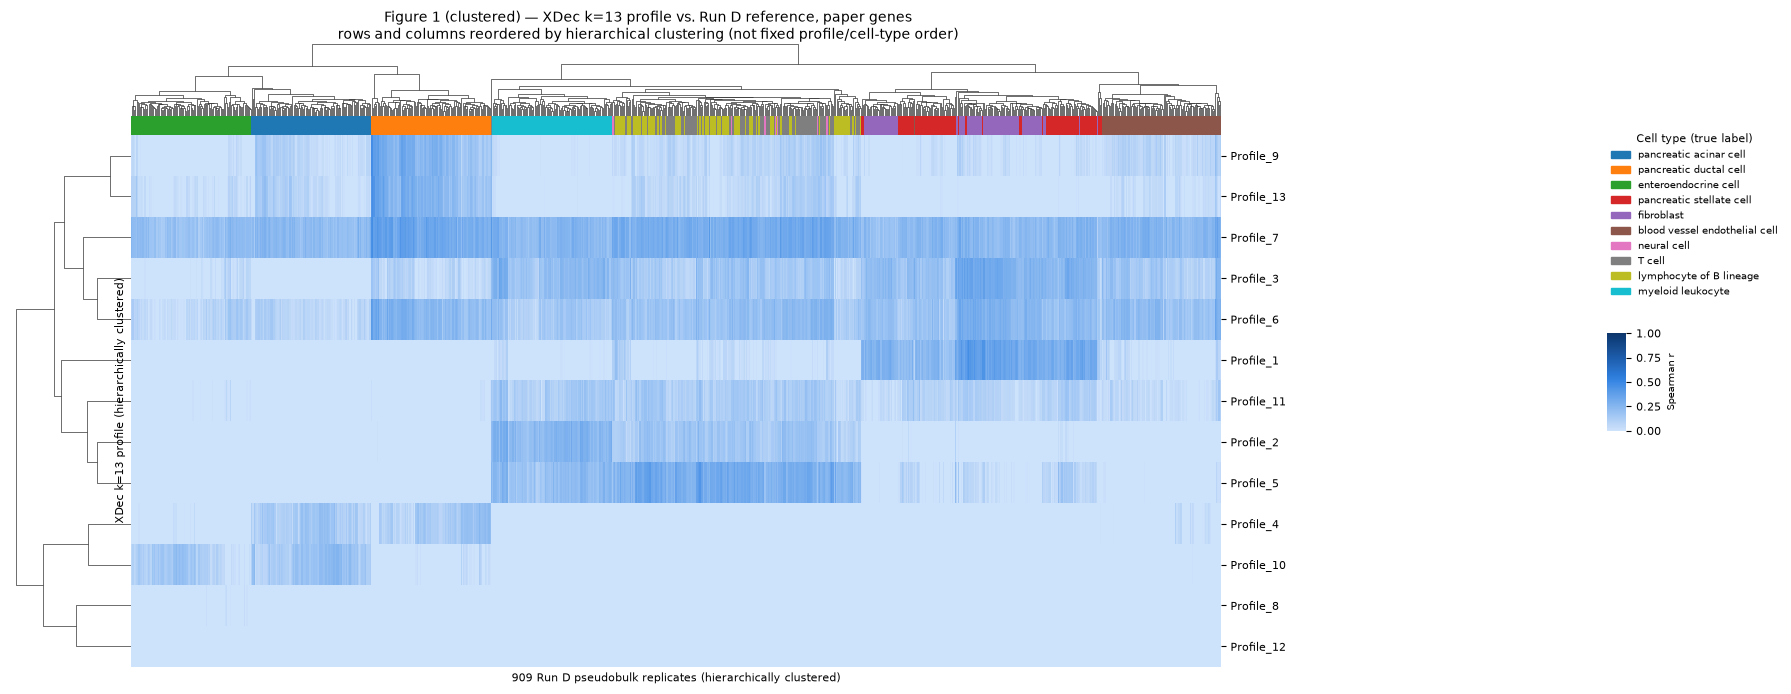

saved xdec_autotuned_n150/figures/fig09_figure1_k13_profile_reference_CLUSTERED.png


In [4]:
genes_1 = [g for g in paper_genes if g in reference_means.index and g in profiles_k13.index]
print(f"Figure 1: {len(genes_1)} shared paper-gene probes (same gene list as notebook 08's fixed-order version)")

combined_1 = pd.concat([reference_means.loc[genes_1], profiles_k13.loc[genes_1, profile_order]], axis=1)
corr_1_full = combined_1.corr(method="spearman")
corr_1 = corr_1_full.loc[profile_order, pb_order]
if not np.isfinite(corr_1.to_numpy()).all():
    raise ValueError("Undefined correlations in Figure 1")

grid = sns.clustermap(
    corr_1, row_cluster=True, col_cluster=True, metric="euclidean", method="average",
    col_colors=pb_cell_types.loc[pb_order].map(cell_palette).to_numpy(),
    cmap=seq_blue, vmin=0.0, vmax=1.0,
    xticklabels=False, yticklabels=True, figsize=(13, 6.5),
    cbar_kws={"label": "Spearman r", "ticks": [0, 0.25, 0.5, 0.75, 1]}, dendrogram_ratio=(0.10, 0.12),
)
grid.ax_heatmap.set_xlabel(f"{len(pb_order)} Run D pseudobulk replicates (hierarchically clustered)")
grid.ax_heatmap.set_ylabel("XDec k=13 profile (hierarchically clustered)")
grid.ax_heatmap.yaxis.set_label_position("left")
grid.ax_heatmap.tick_params(axis="y", rotation=0)

handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
legend = grid.ax_heatmap.legend(
    handles, cell_type_order, title="Cell type (true label)", bbox_to_anchor=(1.35, 1.02),
    loc="upper left", fontsize=7, title_fontsize=8, frameon=False,
)
grid.fig.suptitle("Figure 1 (clustered) — XDec k=13 profile vs. Run D reference, paper genes\n"
                   "rows and columns reordered by hierarchical clustering (not fixed profile/cell-type order)",
                   y=1.03, fontsize=10)
grid.fig.canvas.draw()
bbox = legend.get_window_extent(grid.fig.canvas.get_renderer()).transformed(grid.fig.transFigure.inverted())
grid.cax.set_position([bbox.x0, bbox.y0 - 0.20, 0.015, 0.15])
grid.cax.yaxis.label.set_fontsize(7)

fig1_path = figures_dir / "fig09_figure1_k13_profile_reference_CLUSTERED.png"
grid.savefig(fig1_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(grid.fig)
print("saved", fig1_path)


### Figure 2 (clustered) — CIBERSORTx's own signature matrix vs. the same Run D reference, hierarchically clustered

3671 genes shared between CIBERSORTx's own signature matrix and the Run D reference (CIBERSORTx's own auto-selected gene list, NOT the paper's 282-gene list)


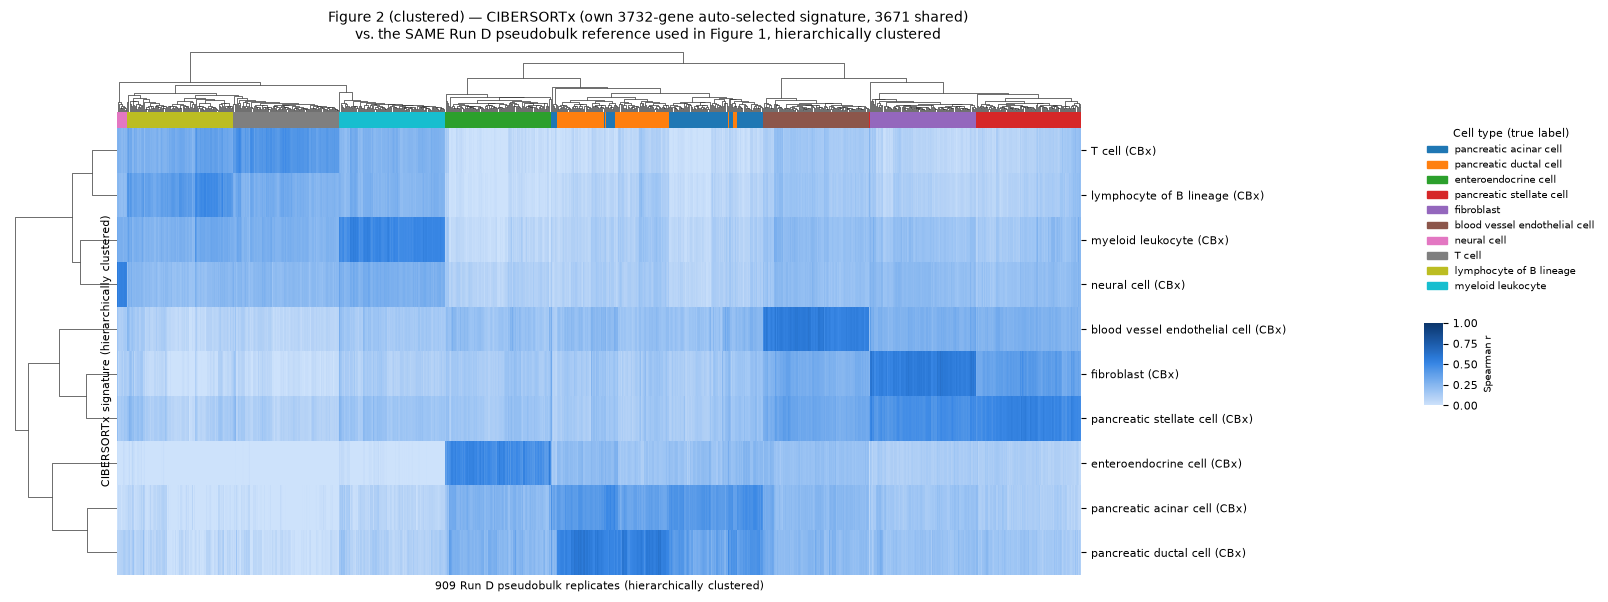

saved xdec_autotuned_n150/figures/fig09_figure2_cibersortx_sigmatrix_vs_refD_CLUSTERED.png

Diagonal check (row's own cell-type mean vs. row's max cell-type mean -- order-independent, still valid under clustering):
  pancreatic acinar cell           own=0.43  row_max=0.43 (pancreatic acinar cell)
  pancreatic ductal cell           own=0.54  row_max=0.54 (pancreatic ductal cell)
  enteroendocrine cell             own=0.48  row_max=0.48 (enteroendocrine cell)
  pancreatic stellate cell         own=0.50  row_max=0.50 (pancreatic stellate cell)
  fibroblast                       own=0.56  row_max=0.56 (fibroblast)
  blood vessel endothelial cell    own=0.55  row_max=0.55 (blood vessel endothelial cell)
  neural cell                      own=0.53  row_max=0.53 (neural cell)
  T cell                           own=0.42  row_max=0.42 (T cell)
  lymphocyte of B lineage          own=0.41  row_max=0.41 (lymphocyte of B lineage)
  myeloid leukocyte                own=0.50  row_max=0.50 (myeloid le

In [5]:
sigmatrix_renamed = sigmatrix.rename(columns=lambda c: f"{c} (CBx)")
sig_row_order = [f"{c} (CBx)" for c in cols10]
genes_2 = [g for g in sigmatrix.index if g in reference_means.index]
print(f"{len(genes_2)} genes shared between CIBERSORTx's own signature matrix and the Run D reference "
      f"(CIBERSORTx's own auto-selected gene list, NOT the paper's 282-gene list)")
if len(genes_2) < 10:
    raise ValueError("Too few shared genes for Figure 2")

combined_2 = pd.concat([reference_means.loc[genes_2], sigmatrix_renamed.loc[genes_2]], axis=1)
expected_cols = len(pb_order) + 10
if combined_2.shape[1] != expected_cols or not combined_2.columns.is_unique:
    raise ValueError(f"Expected {expected_cols} uniquely-named columns ({len(pb_order)} reference pseudobulk + 10 renamed CIBERSORTx)")
corr_2_full = combined_2.corr(method="spearman")
corr_2 = corr_2_full.loc[sig_row_order, pb_order]
if not np.isfinite(corr_2.to_numpy()).all():
    raise ValueError("Undefined correlations in Figure 2")

grid = sns.clustermap(
    corr_2, row_cluster=True, col_cluster=True, metric="euclidean", method="average",
    col_colors=pb_cell_types.loc[pb_order].map(cell_palette).to_numpy(),
    cmap=seq_blue, vmin=0.0, vmax=1.0,
    xticklabels=False, yticklabels=True, figsize=(13, 5.5),
    cbar_kws={"label": "Spearman r", "ticks": [0, 0.25, 0.5, 0.75, 1]}, dendrogram_ratio=(0.10, 0.12),
)
grid.ax_heatmap.set_xlabel(f"{len(pb_order)} Run D pseudobulk replicates (hierarchically clustered)")
grid.ax_heatmap.set_ylabel("CIBERSORTx signature (hierarchically clustered)")
grid.ax_heatmap.yaxis.set_label_position("left")
grid.ax_heatmap.tick_params(axis="y", rotation=0)

handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
legend = grid.ax_heatmap.legend(
    handles, cell_type_order, title="Cell type (true label)", bbox_to_anchor=(1.35, 1.02),
    loc="upper left", fontsize=7, title_fontsize=8, frameon=False,
)
grid.fig.suptitle(
    f"Figure 2 (clustered) — CIBERSORTx (own {len(sigmatrix.index)}-gene auto-selected signature, {len(genes_2)} shared)\n"
    f"vs. the SAME Run D pseudobulk reference used in Figure 1, hierarchically clustered",
    y=1.05, fontsize=10,
)
grid.fig.canvas.draw()
bbox = legend.get_window_extent(grid.fig.canvas.get_renderer()).transformed(grid.fig.transFigure.inverted())
grid.cax.set_position([bbox.x0, bbox.y0 - 0.20, 0.015, 0.15])
grid.cax.yaxis.label.set_fontsize(7)

fig2_path = figures_dir / "fig09_figure2_cibersortx_sigmatrix_vs_refD_CLUSTERED.png"
grid.savefig(fig2_path, dpi=200, bbox_inches="tight")
corr_2.to_csv(fig2_path.with_suffix(".tsv"), sep="\t")
plt.show()
plt.close(grid.fig)
print("saved", fig2_path)
print("\nDiagonal check (row's own cell-type mean vs. row's max cell-type mean -- order-independent, still valid under clustering):")
pb_type_of_col = pb_cell_types.loc[pb_order]
for ct in cell_type_order:
    row = corr_2.loc[f"{ct} (CBx)"]
    type_means = row.groupby(pb_type_of_col.values).mean()
    own = type_means[ct]
    print(f"  {ct:32s} own={own:.2f}  row_max={type_means.max():.2f} ({type_means.idxmax()})")


### Figure 3 — proportion scatter with y=x reference line

CIBERSORTx restricted to 150 samples shared with XDec k=13's n=150 cohort


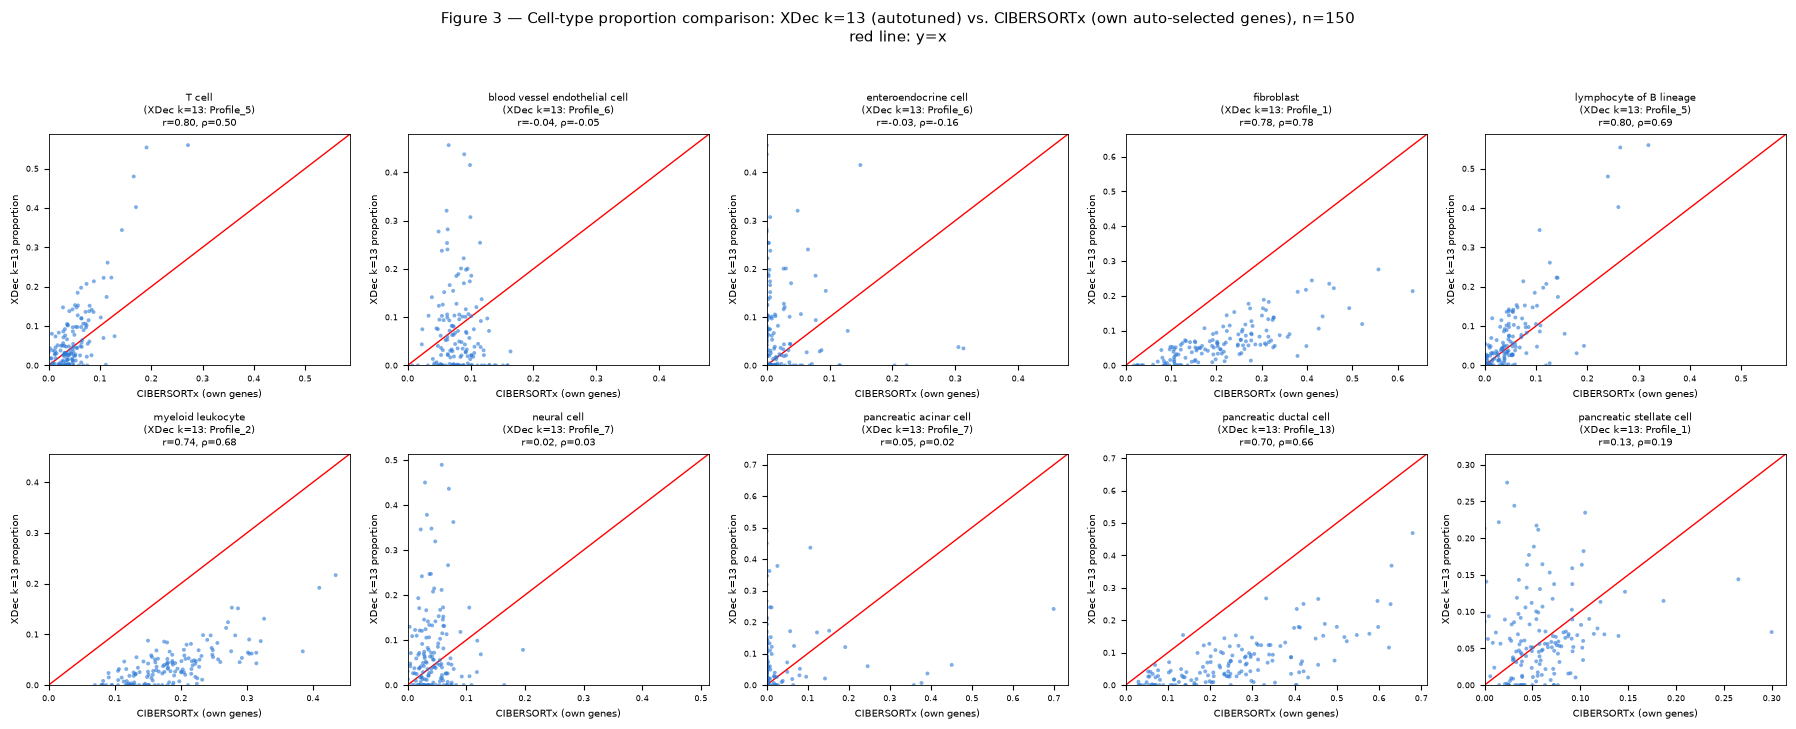

saved xdec_autotuned_n150/figures/fig09_proportion_scatter_k13_vs_cibersortx.png


,xdec_k13_matched_profile,pearson_r,pearson_p,spearman_r,spearman_p
reference_cell_type,,,,,
lymphocyte of B lineage,Profile_5,0.800875,8.955054e-35,0.688130,2.276760e-22
T cell,Profile_5,0.798079,2.247186e-34,0.496964,9.891862e-11
fibroblast,Profile_1,0.776490,1.736465e-31,0.775254,2.484390e-31
myeloid leukocyte,Profile_2,0.735298,8.809321e-27,0.682754,6.417620e-22
pancreatic ductal cell,Profile_13,0.701793,1.473616e-23,0.658311,5.469168e-20
pancreatic stellate cell,Profile_1,0.129063,1.154723e-01,0.192871,1.804656e-02
pancreatic acinar cell,Profile_7,0.051018,5.352501e-01,0.018836,8.190357e-01
neural cell,Profile_7,0.017166,8.348384e-01,0.029647,7.187377e-01
enteroendocrine cell,Profile_6,-0.032984,6.886437e-01,-0.156627,5.561125e-02


In [6]:
n150_samples = proportions_k13.index
bc16_to_full = pd.Series(n150_samples.values, index=n150_samples.str[:16])
ciber_bc16 = ciber_full.index.str[:16]
keep = ciber_bc16.isin(bc16_to_full.index)
ciber_150 = ciber_full.loc[keep].copy()
ciber_150.index = bc16_to_full.loc[ciber_bc16[keep].values].values
if set(ciber_150.index) != set(n150_samples):
    raise ValueError("CIBERSORTx 150-sample subset does not exactly match the XDec k=13 n=150 cohort")
print(f"CIBERSORTx restricted to {ciber_150.shape[0]} samples shared with XDec k=13's n=150 cohort")

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
scatter_rows = []
for ax, ct in zip(axes.flat, REFERENCE_CELL_TYPES):
    matched_profile = assignment_k13.loc[ct, "best_profile"]
    x = ciber_150[ct]
    y = proportions_k13.loc[x.index, matched_profile]
    pear_r, pear_p = pearsonr(x, y)
    spear_r, spear_p = spearmanr(x, y)
    scatter_rows.append({"reference_cell_type": ct, "xdec_k13_matched_profile": matched_profile,
                          "pearson_r": pear_r, "pearson_p": pear_p,
                          "spearman_r": spear_r, "spearman_p": spear_p})

    lim = float(max(x.max(), y.max())) * 1.05
    ax.plot([0, lim], [0, lim], color="red", linewidth=1.0, linestyle="-", zorder=1)
    ax.scatter(x, y, s=8, alpha=0.6, color="#2a78d6", edgecolor="none", zorder=2)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_title(f"{ct}\n(XDec k=13: {matched_profile})\nr={pear_r:.2f}, ρ={spear_r:.2f}", fontsize=7.5)
    ax.set_xlabel("CIBERSORTx (own genes)", fontsize=7)
    ax.set_ylabel("XDec k=13 proportion", fontsize=7)
    ax.tick_params(labelsize=6)

fig.suptitle("Figure 3 — Cell-type proportion comparison: XDec k=13 (autotuned) vs. CIBERSORTx (own auto-selected genes), n=150\n"
             "red line: y=x", y=1.03, fontsize=11)
fig.tight_layout()
fig3_path = figures_dir / "fig09_proportion_scatter_k13_vs_cibersortx.png"
fig.savefig(fig3_path, dpi=200, bbox_inches="tight")
scatter_stats_df = pd.DataFrame(scatter_rows).set_index("reference_cell_type")
scatter_stats_df.to_csv(figures_dir / "fig09_proportion_scatter_k13_vs_cibersortx_stats.tsv", sep="\t")
plt.show()
plt.close(fig)
print("saved", fig3_path)
scatter_stats_df.sort_values("pearson_r", ascending=False)
